# Cambios del Script $04/10/26$ — Topografía real (DEM ALOS PALSAR)
- ### Nuevo `TOPO_SCENARIO = 4`: $z_b(x,y)$ sale del DEM ALOS PALSAR 12.5 m generado en `DEM/DEM2.ipynb`
- ### Marco local rotado: $x$ aguas abajo desde el punto de inicio, $y$ transversal (izquierda del flujo); el eje $x$ sigue la línea de máxima pendiente
- ### $z_b$ y $\nabla z_b$ se precalculan en una grilla (DEM suavizado) y se interpolan bilinealmente en TensorFlow
- ### En la EDP de momento $\partial_x H = \partial_x h + \partial_x z_b$, con $\partial_x z_b$ de `grad_zb_fixed` (z_b ya no entra a la cinta)
- ### `S_ref` se calcula desde el DEM (pendiente mediana a lo largo del cauce)
- ### La condición inicial se ubica sobre el cauce (`IC_X0`, `IC_Y0`)
- ### Nuevas figuras: mapa del dominio sobre el DEM y mapa de inundación $h_{max}$ en UTM

# Cambios del Script $22/06/26$
- ### Se agrega un Ansatz con la condicion inicial
- ### Dado el Ansatz se quita $Loss_{ic}$
- ### Cinco Capas ocultas con 72 neuronas y SWISH cada una  

In [1]:
# ============================================================
# PINN para lahar por etapas (z_b fijo, sin Exner)
# Aprende: h, u, v, C, p
# ============================================================
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, optimizers #type: ignore
import matplotlib.pyplot as plt
tf.random.set_seed(7)
np.random.seed(7)

I0000 00:00:1791845520.419584   12658 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791845520.917055   12658 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791845522.933379   12658 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# ============================================================
# SELECCIÓN DE TOPOGRAFÍA
# ============================================================
TOPO_SCENARIO = 4 # 1: plano inclinado, 2: valle parabólico, 3: valle convergente, 4: DEM ALOS PALSAR

# --- Solo para TOPO_SCENARIO = 4 (DEM) ---
DEM_PATH = "DEM/villarrica_dem_alos_utm19s.tif"  # GeoTIFF UTM 19S generado con DEM/DEM2.ipynb
# Punto de inicio (x = 0, pared aguas arriba). Por defecto: a SRC_DIST_M de la cumbre con rumbo SRC_AZ_DEG.
# Para fijarlo a mano, da SRC_LON, SRC_LAT (grados WGS84) y se ignoran SRC_AZ_DEG / SRC_DIST_M.
SRC_LON, SRC_LAT = None, None
SRC_AZ_DEG = 0.0        # rumbo cumbre -> inicio (0 = N, 90 = E). 0: flanco norte, cauce hacia Pucón
SRC_DIST_M = 1500.0     # distancia cumbre -> inicio [m]
FLOW_AZ_DEG = None      # rumbo del eje x; None = automático (línea de máxima pendiente)
ZB_SMOOTH_M = 50.0      # sigma del suavizado gaussiano del DEM [m] (quita ruido de 12.5 m)
ZB_GRID_M = 25.0        # resolución de la grilla de z_b que usa la PINN [m]
# ============================================================
# 1) PARÁMETROS FÍSICOS
# ============================================================
g = 9.81
rho_m = 1800.0
mu0 = 0.20
alpha_C = 1.2
alpha_p = 4.0
C0 = 0.45
p_ref = 1e4
kappa_C = 0.0 #5.0
tau_C = 1e9 # relajación casi nula para C
tau_p = 120.0
chi_p = 0.8 #0.35
# lambda = p/(rho_m g h) inicial. Con mu0=0.2 y pendiente 8% el lahar necesita
# lambda > ~0.29 para que mu_eff < tan(theta); con 0.2 quedaba bloqueado.
lambda_0 = 0.60
# Piso hidrostático: un lahar está SATURADO en agua, así que su presión de poros
# basal nunca baja de la del fluido intersticial, p >= rho_f g h (Iverson 1997).
# En lambda: lambda >= rho_f/rho_m ~ 0.556. Con este piso mu_eff <~ 0.03 < tan(theta)
# en el cuerpo del lahar: el estado "detenido" deja de ser solución de las EDP.
rho_f = 1000.0                   # densidad del fluido intersticial [kg/m3]
lambda_hydro = rho_f / rho_m     # ~0.556
assert lambda_0 >= lambda_hydro, "lambda_0 no puede ser menor que el piso hidrostático"
# Pared impermeable aguas arriba (x = 0): u = 0 exacto -> no entra masa desde fuera
ell_wall = 250.0                 # [m] longitud de la función distancia
# Rampa temporal del ansatz: omega = 1 - exp(-t/t_ramp). Antes era T/5 = 240 s,
# más lenta que la relajación de p (tau_p = 120 s): la red no alcanzaba a acelerar.
t_ramp = 20.0        # [s]
# Resistencia turbulenta de Voellmy: g|u|u/(xi h). Sin ella, con mu_eff < tan(theta)
# el flujo acelera sin límite (a = g(sin - mu cos) = cte).
xi_voellmy = 500.0   # [m/s2]
h_dry = 0.05         # [m] regularización de 1/h en zona seca
# Restricción integral de volumen: V(t) + (volumen que salió por x = Lx) = V0
lambda_vol = 1.0e4
S_ref = 0.08         # pendiente característica del valle (TOPO_SCENARIO = 4: se recalcula desde el DEM)
# Currículo temporal: el horizonte de entrenamiento crece de T_curr0 a Tmax en la etapa 2.
# Primero la red aprende el ARRANQUE (aceleración) y luego lo prolonga en el tiempo.
T_curr0 = 60.0       # [s]
t_early = 120.0      # [s] ventana de arranque sobre-muestreada (25% de cada batch)
u_star = 1.0
C_star = 0.05
eps_u = 1e-3
eps_h = 1e-6
# ============================================================
# 2) DOMINIO
# ============================================================
Lx = 10_000.0
Ly = 2_000.0
Tmax = 1200.0
x_min, x_max = 0.0, Lx
y_min, y_max = -Ly/2, Ly/2
t_min, t_max = 0.0, Tmax
# Centro de la condición inicial (montículo gaussiano). Con el DEM, IC_Y0 se mueve al cauce.
IC_X0, IC_Y0 = 1200.0, 0.0
# Normalización
x_scale = Lx
y_scale = Ly/2
t_scale = Tmax
h_scale = 10.0
u_scale = 10.0
p_scale = rho_m * g * h_scale

In [3]:
# ============================================================
# 3) TOPOGRAFÍA FIJA z_b(x,y)
# ============================================================
# Escenarios 1-3: funciones analíticas. Escenario 4: DEM ALOS PALSAR (DEM/DEM2.ipynb).
#
# Con el DEM se usa un marco LOCAL ROTADO, igual al de los escenarios analíticos:
#   x : distancia aguas abajo desde el punto de inicio (x = 0 es la pared impermeable)
#   y : distancia transversal, positiva hacia la izquierda del flujo (sistema derecho)
# Las EDP de aguas someras son invariantes ante rotaciones: u y v pasan a ser las
# componentes de la velocidad a lo largo y a través del eje x.
#
# z_b y su gradiente se precalculan en una grilla regular (ZB_GRID_M) desde el DEM suavizado
# (ZB_SMOOTH_M) y se interpolan bilinealmente en TensorFlow. El gradiente NO se obtiene
# derivando la interpolación (sería constante por celda y discontinuo): se interpola la
# grilla del gradiente, así g*dz_b/dx es continuo.

def zb_analytic(x, y):
    if TOPO_SCENARIO == 1:
        # Plano inclinado (Pendiente 10%) - Usar solo para calibrar
        Sx = 0.10
        z0 = 3000.0
        return z0 - Sx * x

    elif TOPO_SCENARIO == 2:
        # Valle Parabólico Suave (Aproximación Villarrica / Quebrada)
        Sx = 0.08         # Pendiente longitudinal (8%)
        z0 = 2900.0       # Altitud base

        # Curvatura del valle.
        # A y=1000m, las paredes suben 50 metros respecto al centro.
        # Esto confina el flujo sin generar gradientes explosivos.
        k_y = 50.0 / (1000.0**2)

        return (z0 - Sx * x) + k_y * (y**2)

    else:
        # Valle Convergente (Embudamiento)
        # El canal se hace más estrecho a medida que se desciende
        Sx = 0.08
        z0 = 2900.0
        # La pendiente transversal aumenta linealmente con 'x'
        k_y = (20.0 + 0.01 * x) / (1000.0**2)
        return (z0 - Sx * x) + k_y * (y**2)


if TOPO_SCENARIO == 4:
    import rasterio
    from pyproj import Transformer
    from scipy.ndimage import gaussian_filter, map_coordinates

    # --- DEM suavizado y su gradiente en UTM ---
    with rasterio.open(DEM_PATH) as src:
        dem = src.read(1).astype(np.float64)
        dem_tr, dem_crs = src.transform, src.crs
    if np.isnan(dem).any():
        raise ValueError(f"{DEM_PATH} tiene píxeles sin dato: regenera el DEM sin allow_nan.")
    dem_res = dem_tr.a
    dem_s = gaussian_filter(dem, ZB_SMOOTH_M / dem_res, mode="nearest")
    dzdE = np.gradient(dem_s, dem_res, axis=1)
    dzdN = -np.gradient(dem_s, dem_res, axis=0)   # las filas crecen hacia el sur

    def dem_sample(A, E, N):
        """Interpola A (grilla del DEM) en coordenadas UTM (E, N). Fuera del DEM -> NaN."""
        E, N = np.asarray(E, dtype=float), np.asarray(N, dtype=float)
        r = (dem_tr.f - N) / dem_res - 0.5
        c = (E - dem_tr.c) / dem_res - 0.5
        out = map_coordinates(A, [r.ravel(), c.ravel()], order=1, mode="constant", cval=np.nan)
        return out.reshape(E.shape)

    # --- Punto de inicio (origen del marco local) ---
    r_top, c_top = np.unravel_index(np.argmax(dem_s), dem.shape)
    E_top = dem_tr.c + (c_top + 0.5) * dem_res
    N_top = dem_tr.f - (r_top + 0.5) * dem_res
    if SRC_LON is None:
        E_src = E_top + SRC_DIST_M * np.sin(np.radians(SRC_AZ_DEG))
        N_src = N_top + SRC_DIST_M * np.cos(np.radians(SRC_AZ_DEG))
    else:
        E_src, N_src = Transformer.from_crs("EPSG:4326", dem_crs, always_xy=True).transform(SRC_LON, SRC_LAT)

    # --- Línea de máxima pendiente desde el inicio (aprox. el cauce) ---
    def flow_path(E, N, L, ds):
        P = [(E, N)]
        for _ in range(int(L / ds)):
            gE, gN = dem_sample(dzdE, E, N), dem_sample(dzdN, E, N)
            gnorm = np.hypot(gE, gN)
            if not np.isfinite(gnorm) or gnorm < 1e-3:   # salió del DEM o llegó a un plano/hoyo
                break
            E, N = E - ds * gE / gnorm, N - ds * gN / gnorm
            P.append((E, N))
        return np.array(P)

    ds_path = 0.5 * dem_res
    path_EN = flow_path(E_src, N_src, 1.5 * Lx, ds_path)
    if FLOW_AZ_DEG is None:
        # Rumbo de la cuerda entre el inicio y el punto del cauce a 0.7*Lx de recorrido
        k = min(len(path_EN) - 1, int(0.7 * Lx / ds_path))
        dE, dN = path_EN[k] - path_EN[0]
        flow_az = float(np.degrees(np.arctan2(dE, dN)) % 360.0)
    else:
        flow_az = float(FLOW_AZ_DEG)
    ex = np.array([np.sin(np.radians(flow_az)), np.cos(np.radians(flow_az))])  # eje x en (E, N)
    ey = np.array([-ex[1], ex[0]])                                            # eje y: x girado 90° antihorario

    def local_to_utm(x, y):
        return E_src + x * ex[0] + y * ey[0], N_src + x * ex[1] + y * ey[1]

    def utm_to_local(E, N):
        dE, dN = np.asarray(E) - E_src, np.asarray(N) - N_src
        return dE * ex[0] + dN * ex[1], dE * ey[0] + dN * ey[1]

    # --- Grillas de z_b, dz_b/dx, dz_b/dy en el marco local (con margen en las fronteras) ---
    _m = 2 * ZB_GRID_M
    xg_zb = np.arange(x_min - _m, x_max + _m + 0.5 * ZB_GRID_M, ZB_GRID_M)
    yg_zb = np.arange(y_min - _m, y_max + _m + 0.5 * ZB_GRID_M, ZB_GRID_M)
    XZ, YZ = np.meshgrid(xg_zb, yg_zb, indexing="xy")
    EZ, NZ = local_to_utm(XZ, YZ)
    zb_grid = dem_sample(dem_s, EZ, NZ)
    if np.isnan(zb_grid).any():
        raise ValueError(
            "El dominio de la PINN se sale del DEM. Agranda HALF_X_KM / HALF_Y_KM en DEM/DEM2.ipynb "
            "(y vuelve a guardar el GeoTIFF), o reduce Lx / Ly, o cambia el punto de inicio.")
    # Gradiente en el marco local = gradiente UTM proyectado sobre los ejes (sin re-derivar)
    gE, gN = dem_sample(dzdE, EZ, NZ), dem_sample(dzdN, EZ, NZ)
    zbx_grid = gE * ex[0] + gN * ex[1]
    zby_grid = gE * ey[0] + gN * ey[1]

    # --- Cauce en coordenadas locales: ubica la condición inicial sobre él ---
    path_x, path_y = utm_to_local(path_EN[:, 0], path_EN[:, 1])
    k_ic = int(np.argmax(path_x >= IC_X0)) if (path_x >= IC_X0).any() else len(path_x) - 1
    IC_Y0 = float(path_y[k_ic])

    # Pendiente característica: mediana de |grad z_b| a lo largo del cauce dentro del dominio
    in_dom = (path_x >= 0) & (path_x <= Lx) & (np.abs(path_y) <= Ly / 2)
    S_path = np.hypot(dem_sample(dzdE, *path_EN[in_dom].T), dem_sample(dzdN, *path_EN[in_dom].T))
    S_ref = float(np.median(S_path))

    # --- Interpolación bilineal en TensorFlow ---
    _zb_stack = tf.constant(np.stack([zb_grid, zbx_grid, zby_grid], axis=-1)
                            .reshape(-1, 3).astype(np.float32))
    _gx0, _gy0 = float(xg_zb[0]), float(yg_zb[0])
    _gnx, _gny = len(xg_zb), len(yg_zb)

    def _zb_interp(xm, ym):
        """(z_b, dz_b/dx, dz_b/dy) en puntos (xm, ym) de forma (N, 1). Devuelve (N, 3)."""
        fx = tf.clip_by_value((xm - _gx0) / ZB_GRID_M, 0.0, _gnx - 1.001)
        fy = tf.clip_by_value((ym - _gy0) / ZB_GRID_M, 0.0, _gny - 1.001)
        i0, j0 = tf.floor(fx), tf.floor(fy)
        wx, wy = fx - i0, fy - j0
        idx = tf.cast(j0, tf.int32) * _gnx + tf.cast(i0, tf.int32)
        g = lambda k: tf.reshape(tf.gather(_zb_stack, k), (-1, 3))
        z00, z01 = g(idx), g(idx + 1)
        z10, z11 = g(idx + _gnx), g(idx + _gnx + 1)
        out = (1 - wy) * ((1 - wx) * z00 + wx * z01) + wy * ((1 - wx) * z10 + wx * z11)
        return tf.stop_gradient(out)

    print(f"DEM: {DEM_PATH}  ({dem.shape[0]} x {dem.shape[1]} px, {dem_res:.1f} m)")
    print(f"Inicio (x=0): E={E_src:.0f} N={N_src:.0f} (UTM 19S), z={dem_sample(dem_s, E_src, N_src):.0f} m")
    print(f"Rumbo del eje x: {flow_az:.1f}° {'(automático)' if FLOW_AZ_DEG is None else '(manual)'}")
    print(f"Cauce: {len(path_EN) * ds_path:.0f} m de recorrido; desviación lateral máx. dentro del dominio: "
          f"{np.abs(path_y[(path_x >= 0) & (path_x <= Lx)]).max():.0f} m (Ly/2 = {Ly / 2:.0f} m)")
    print(f"z_b en el dominio: {zb_grid.min():.0f} a {zb_grid.max():.0f} m | "
          f"S_ref = {S_ref:.3f} (pendiente mediana del cauce) | IC en (x, y) = ({IC_X0:.0f}, {IC_Y0:.0f}) m")


def zb0_physical(x, y):
    if TOPO_SCENARIO == 4:
        return _zb_interp(x, y)[:, 0:1]
    return zb_analytic(x, y)

def grad_zb_fixed(x, y):
    """
    Gradiente de la topografía fija.
    DEM: interpolado de la grilla precalculada. Analítico: con GradientTape
    (se calcula aparte para evitar NoneType en Graph mode).
    """
    if TOPO_SCENARIO == 4:
        out = _zb_interp(x, y)
        return out[:, 1:2], out[:, 2:3]
    with tf.GradientTape(persistent=True) as tape:
        tape.watch([x, y])
        zb = zb_analytic(x, y)
    zb_x = tape.gradient(zb, x)
    zb_y = tape.gradient(zb, y)
    del tape
    return zb_x, zb_y


W0000 00:00:1791845526.486673   12658 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1791845526.488685   12658 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1791845526.679258   12658 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13209 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070 Ti, pci bus id: 0000:01:00.0, compute capability: 12.0a


DEM: DEM/villarrica_dem_alos_utm19s.tif  (3360 x 3360 px, 12.5 m)
Inicio (x=0): E=246967 N=5633907 (UTM 19S), z=2193 m
Rumbo del eje x: 334.6° (automático)
Cauce: 15006 m de recorrido; desviación lateral máx. dentro del dominio: 663 m (Ly/2 = 1000 m)
z_b en el dominio: 565 a 2264 m | S_ref = 0.097 (pendiente mediana del cauce) | IC en (x, y) = (1200, -207) m


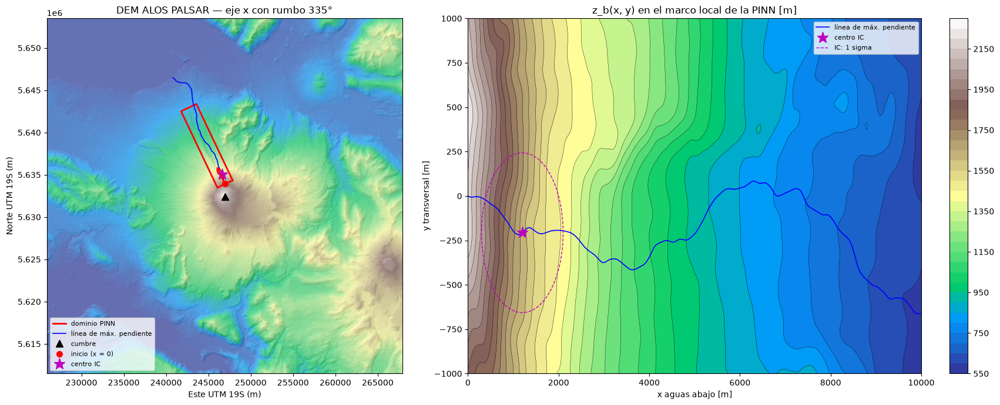

In [4]:
# ============================================================
# 3b) MAPA DEL DOMINIO SOBRE EL DEM (solo TOPO_SCENARIO = 4)
# ============================================================
# Revisa aquí, ANTES de entrenar, que el rectángulo rojo siga el cauce y que la
# condición inicial (estrella) quede dentro de él.
if TOPO_SCENARIO == 4:
    from matplotlib.colors import LightSource
    ext_dem = (dem_tr.c, dem_tr.c + dem.shape[1] * dem_res, dem_tr.f - dem.shape[0] * dem_res, dem_tr.f)
    hill_dem = LightSource(azdeg=315, altdeg=45).hillshade(dem, dx=dem_res, dy=dem_res)
    _cx = np.array([x_min, x_max, x_max, x_min, x_min])
    _cy = np.array([y_min, y_min, y_max, y_max, y_min])
    cE, cN = local_to_utm(_cx, _cy)                 # esquinas del dominio en UTM
    E_ic, N_ic = local_to_utm(IC_X0, IC_Y0)

    fig, ax = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1, 1.5]})
    ax[0].imshow(dem, cmap="terrain", extent=ext_dem)
    ax[0].imshow(hill_dem, cmap="gray", alpha=0.35, extent=ext_dem)
    ax[0].plot(cE, cN, "r-", lw=2, label="dominio PINN")
    ax[0].plot(path_EN[:, 0], path_EN[:, 1], "b-", lw=1.2, label="línea de máx. pendiente")
    ax[0].plot(E_top, N_top, "k^", ms=9, label="cumbre")
    ax[0].plot(E_src, N_src, "ro", ms=7, label="inicio (x = 0)")
    ax[0].plot(E_ic, N_ic, "m*", ms=14, label="centro IC")
    ax[0].annotate("", xy=(E_src + 2500 * ex[0], N_src + 2500 * ex[1]), xytext=(E_src, N_src),
                   arrowprops=dict(arrowstyle="->", color="r", lw=2))
    ax[0].set_title(f"DEM ALOS PALSAR — eje x con rumbo {flow_az:.0f}°")
    ax[0].set_xlabel("Este UTM 19S (m)"); ax[0].set_ylabel("Norte UTM 19S (m)")
    ax[0].legend(fontsize=8, loc="lower left")

    cs = ax[1].contourf(xg_zb, yg_zb, zb_grid, levels=40, cmap="terrain")
    ax[1].contour(xg_zb, yg_zb, zb_grid, levels=np.arange(0, 3000, 50), colors="k", linewidths=0.3)
    ax[1].plot(path_x, path_y, "b-", lw=1.2, label="línea de máx. pendiente")
    ax[1].plot(IC_X0, IC_Y0, "m*", ms=14, label="centro IC")
    _th = np.linspace(0, 2 * np.pi, 100)
    ax[1].plot(IC_X0 + 900 * np.cos(_th), IC_Y0 + 450 * np.sin(_th), "m--", lw=1, label="IC: 1 sigma")
    ax[1].set_xlim(x_min, x_max); ax[1].set_ylim(y_min, y_max)
    ax[1].set_title("z_b(x, y) en el marco local de la PINN [m]")
    ax[1].set_xlabel("x aguas abajo [m]"); ax[1].set_ylabel("y transversal [m]")
    ax[1].legend(fontsize=8, loc="upper right")
    plt.colorbar(cs, ax=ax[1])
    plt.tight_layout(); plt.show()
else:
    print("TOPO_SCENARIO analítico: no hay mapa del DEM.")


In [5]:
# ============================================================
# 4) CONDICIONES INICIALES
# ============================================================
def ic_h_physical(x, y):
    x0, y0 = IC_X0, IC_Y0
    sigx, sigy = 900.0, 450.0
    h0 = 8.0
    return h0 * tf.exp(-((x - x0)**2 / (2 * sigx**2) + (y - y0)**2 / (2 * sigy**2)))

def ic_u_physical(x, y):
    return tf.zeros_like(x)

def ic_v_physical(x, y):
    return tf.zeros_like(y)

def ic_C_physical(x, y):
    C_bg = 0.35 #Minimo
    C_peak = 0.25
    x0, y0 = IC_X0, IC_Y0
    sigx, sigy = 1000.0, 550.0
    C = C_bg + C_peak * tf.exp(-((x - x0)**2 / (2 * sigx**2) + (y - y0)**2 / (2 * sigy**2)))
    return tf.clip_by_value(C, 0.2, 0.75)

def ic_p_physical(x, y):
    return lambda_0 * rho_m * g * ic_h_physical(x, y)


# ============================================================
# 5) MUESTREO DE PUNTOS
# ============================================================
N_ic = 4000
N_pde = 30000
N_bc = 4000

# IC (t=0)
x_ic = tf.random.uniform((N_ic, 1), x_min, x_max, dtype=tf.float32)
y_ic = tf.random.uniform((N_ic, 1), y_min, y_max, dtype=tf.float32)
t_ic = tf.zeros_like(x_ic)

h_ic = ic_h_physical(x_ic, y_ic)
u_ic = ic_u_physical(x_ic, y_ic)
v_ic = ic_v_physical(x_ic, y_ic)
C_ic = ic_C_physical(x_ic, y_ic)
p_ic = ic_p_physical(x_ic, y_ic)

# PDE collocation
# Los puntos PDE se muestrean NUEVOS en cada paso (celda 7, sample_pde_batch):
# horizonte temporal creciente (currículo) + 25% en el arranque [0, t_early].

# BC laterales
x_bc = tf.random.uniform((N_bc, 1), x_min, x_max, dtype=tf.float32)
t_bc = tf.random.uniform((N_bc, 1), t_min, t_max, dtype=tf.float32)
y_bc_top = tf.ones_like(x_bc) * y_max
y_bc_bot = tf.ones_like(x_bc) * y_min

y_bc = tf.random.uniform((N_bc, 1), y_min, y_max, dtype=tf.float32)
t_bc_x = tf.random.uniform((N_bc, 1), t_min, t_max, dtype=tf.float32)
x_bc_left  = tf.ones_like(y_bc) * x_min
x_bc_right = tf.ones_like(y_bc) * x_max

In [6]:
# ============================================================
# 6) RED NEURONAL: (x,y,t) -> (h,u,v,C) (CON ANSATZ EXACTO)
# ============================================================
Cmax = 0.65

inputs = tf.keras.Input(shape=(3,))
x = layers.Dense(72, activation='swish')(inputs)
x = layers.Dense(72, activation='swish')(x)
x = layers.Dense(72, activation='swish')(x)
x = layers.Dense(72, activation='swish')(x)
x = layers.Dense(72, activation='swish')(x)
x = layers.Dense(72, activation='swish')(x)
out_raw = layers.Dense(5, activation='linear')(x)

model = tf.keras.Model(inputs=inputs, outputs=out_raw)

lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=1e-3,
    decay_steps=3000,      
    decay_rate=0.85,        
    staircase=False
)
opt = tf.keras.mixed_precision.LossScaleOptimizer(tf.keras.optimizers.Adam(learning_rate=lr_schedule, clipnorm=1.0))

@tf.function
def predict_fields(xm, ym, tm):
    xn = xm / x_scale
    yn = ym / y_scale
    tn = tm / t_scale
    inp = tf.concat([xn, yn, tn], axis=1)
    raw = model(inp)

    h_raw = raw[:, 0:1]
    u_raw = raw[:, 1:2]
    v_raw = raw[:, 2:3]
    C_raw = raw[:, 3:4]
    p_raw = raw[:, 4:5]

    h0 = ic_h_physical(xm, ym)
    u0 = ic_u_physical(xm, ym)
    v0 = ic_v_physical(xm, ym)
    p0 = ic_p_physical(xm, ym)
    C0_ic = ic_C_physical(xm, ym)

    omega = 1.0 - tf.exp(-tm / t_ramp)

    # Pared impermeable en x = 0: d(x) = 1 - exp(-x/ell) vale 0 en x = 0 -> flujo h*u = 0
    wall_x = 1.0 - tf.exp(-xm / ell_wall)
    u = u0 + omega * wall_x * (u_raw * u_scale)
    v = v0 + omega * (v_raw * u_scale)

    # Blindaje h: Evitar log(0)
    clip_h = tf.clip_by_value(1.0 - tf.exp(-h0), 1e-7, 1.0)
    inv_sp_h0 = h0 + tf.math.log(clip_h)
    h = tf.nn.softplus(inv_sp_h0 + omega * h_raw * h_scale)

    # p = p_hidrostática(h) + p_exceso, con p_exceso >= 0 (mismo ansatz que h).
    # En t=0: p = rho_f g h0 + (p0 - rho_f g h0) = p0 exacto. Sin techo litostático.
    p_hydro = rho_f * g * h
    pex0_n = (p0 - rho_f * g * h0) / p_scale
    clip_p = tf.clip_by_value(1.0 - tf.exp(-pex0_n), 1e-7, 1.0)
    inv_sp_p0 = pex0_n + tf.math.log(clip_p)
    p = p_hydro + p_scale * tf.nn.softplus(inv_sp_p0 + omega * p_raw)   # Pa

    # Blindaje C: Evitar log(0) con clip_by_value
    C0_norm = tf.clip_by_value(C0_ic / Cmax, 1e-7, 1.0 - 1e-7)
    inv_sig_C0 = tf.math.log(C0_norm / (1.0 - C0_norm))
    C = Cmax * tf.math.sigmoid(inv_sig_C0 + omega * C_raw)

    return h, u, v, C, p

In [7]:
# ============================================================
# 7) CIERRES FÍSICOS
# ============================================================
@tf.function
def mu_eff(C, p, h):
    denom = rho_m*g*h + p_ref
    return mu0*(1.0 + alpha_C*(C - C0)) * tf.exp(-alpha_p * (p/denom))

@tf.function
def cos_theta(zb_x, zb_y):
    return 1.0 / tf.sqrt(1.0 + zb_x**2 + zb_y**2)

@tf.function
def p_eq(h, C, u, v):
    speed = tf.sqrt(u**2 + v**2 + eps_u)
    phiC = C / (C + C_star)
    # En reposo p relaja a la hidrostática (no a cero); el corte genera exceso de presión.
    # lambda_eq va de rho_f/rho_m ~ 0.56 (reposo) a ~0.56 + chi_p*0.44*phiC ~ 0.88 (flujo rápido)
    p_hydro = rho_f * g * h
    p_excess = chi_p * (rho_m - rho_f) * g * h * phiC * (speed / (speed + u_star))
    return p_hydro + p_excess

# ============================================================
# 8) RESIDUOS PDE (SIN Exner, z_b FIJO)
# ============================================================
@tf.function
def pde_residuals(xm, ym, tm):
    # Primer y segundo orden para h,u,v,C,p
    with tf.GradientTape(persistent=True) as tape2:
        tape2.watch([xm, ym, tm])
        with tf.GradientTape(persistent=True) as tape1:
            tape1.watch([xm, ym, tm])

            h, u, v, C, p = predict_fields(xm, ym, tm)
            hu = h * u
            hv = h * v

        # 1er orden
        h_t = tape1.gradient(h, tm)
        hu_x = tape1.gradient(hu, xm)
        hv_y = tape1.gradient(hv, ym)

        u_t = tape1.gradient(u, tm)
        u_x = tape1.gradient(u, xm)
        u_y = tape1.gradient(u, ym)

        v_t = tape1.gradient(v, tm)
        v_x = tape1.gradient(v, xm)
        v_y = tape1.gradient(v, ym)

        h_x = tape1.gradient(h, xm)
        h_y = tape1.gradient(h, ym)

        C_t = tape1.gradient(C, tm)
        C_x = tape1.gradient(C, xm)
        C_y = tape1.gradient(C, ym)

        p_t = tape1.gradient(p, tm)
        p_x = tape1.gradient(p, xm)
        p_y = tape1.gradient(p, ym)

    # 2do orden
    C_xx = tape2.gradient(C_x, xm)
    C_yy = tape2.gradient(C_y, ym)

    del tape1
    del tape2

    # Gradiente topografía fija (separado)
    zb_x, zb_y = grad_zb_fixed(xm, ym)

    # Seguridad extra por si alguna derivada sale None
    if C_xx is None:
        C_xx = tf.zeros_like(xm)
    if C_yy is None:
        C_yy = tf.zeros_like(ym)
    if zb_x is None:
        zb_x = tf.zeros_like(xm)
    if zb_y is None:
        zb_y = tf.zeros_like(ym)

    # Superficie libre H = h + z_b. z_b NO entra a la cinta: su gradiente viene de
    # grad_zb_fixed (analítico, o interpolado de la grilla del DEM, que es continuo).
    H_x = h_x + zb_x
    H_y = h_y + zb_y

    # (1) Masa
    S_h = 0.0
    f_mass = h_t + hu_x + hv_y - S_h

    # Fricción basal
    speed = tf.sqrt(u**2 + v**2 + eps_u)
    mu = mu_eff(C, p, h)
    cth = cos_theta(zb_x, zb_y)

    tau_b = mu * rho_m * g * h * cth
    tau_bx = tau_b * (u / (speed + eps_u))
    tau_by = tau_b * (v / (speed + eps_u))

    # Resistencia turbulenta de Voellmy (aceleración)
    turb_x = g * speed * u / (xi_voellmy * (h + h_dry))
    turb_y = g * speed * v / (xi_voellmy * (h + h_dry))

    # (2) Momento x
    f_momx = u_t + u * u_x + v * u_y + g * H_x + tau_bx / (rho_m * (h + eps_h)) + turb_x

    # (3) Momento y
    f_momy = v_t + u * v_x + v * v_y + g * H_y + tau_by / (rho_m * (h + eps_h)) + turb_y

    # (4) Concentración
    C_eq_val = 0.45
    f_C = C_t + u * C_x + v * C_y - (kappa_C * (C_xx + C_yy) + (C_eq_val - C) / tau_C)
    
    # (5) Presión de poros (advección + relajación)
    peq = p_eq(h, C, u, v)
    f_p = p_t + u*p_x + v*p_y - (peq - p)/tau_p


    return f_mass, f_momx, f_momy, f_C, f_p



In [8]:
# ============================================================
# 9) PÉRDIDAS
# ============================================================
# ============================================================
# PÉRDIDA DE FRONTERA (NEUMANN / OPEN BOUNDARY)
# ============================================================

@tf.function
def neumann_C_residual(xb, yb, tb, direction):
    with tf.GradientTape() as tape:
        if direction == 'y':
            tape.watch(yb); _, _, _, C, _ = predict_fields(xb, yb, tb)  # FIX: C es el 4o, no el 5o
            dC_dn = tape.gradient(C, yb)
        else:
            tape.watch(xb); _, _, _, C, _ = predict_fields(xb, yb, tb)  # FIX: C es el 4o, no el 5o
            dC_dn = tape.gradient(C, xb)
    return dC_dn

@tf.function
def loss_bc():
    # --- h: Dirichlet en paredes laterales (igual que antes) ---
    h_top, _, _, _, _ = predict_fields(x_bc, y_bc_top, t_bc)
    h_bot, _, _, _, _ = predict_fields(x_bc, y_bc_bot, t_bc)

    eps = 1e-8
    loss_h_top = tf.reduce_mean(tf.square((h_top - 0.0) / (h_scale + eps)))
    loss_h_bot = tf.reduce_mean(tf.square((h_bot - 0.0) / (h_scale + eps)))

    # --- CORRECCIÓN: C con Neumann homogéneo en LAS 4 FRONTERAS ---
    # Paredes laterales del valle (y = y_min, y_max)
    dC_dy_top = neumann_C_residual(x_bc, y_bc_top, t_bc, 'y')
    dC_dy_bot = neumann_C_residual(x_bc, y_bc_bot, t_bc, 'y')
    # Entrada / salida longitudinal (x = x_min, x_max)
    dC_dx_left  = neumann_C_residual(x_bc_left,  y_bc, t_bc_x, 'x')
    dC_dx_right = neumann_C_residual(x_bc_right, y_bc, t_bc_x, 'x')

    # Escalas para adimensionalizar cada residuo de flujo (misma lógica
    # que scale_mass, scale_mom, scale_C en loss_pde_stage2). Se usa una
    # escala distinta para x e y porque Lx >> Ly y de lo contrario el
    # término en x quedaría sub-penalizado solo por la diferencia de escala
    # geométrica, no por ser realmente más preciso.
    scale_C_y = Cmax / y_scale
    scale_C_x = Cmax / x_scale


    return loss_h_top + loss_h_bot

@tf.function
def loss_pde_stage2(xb, yb, tb):
    f_mass, f_momx, f_momy, f_C, f_p = pde_residuals(xb, yb, tb)
    eps = 1e-8
    scale_mass = h_scale / t_scale
    # Momento: 10x la escala original u_scale/t_scale. Con la original la red violaba la
    # conservación de volumen (~90%); con g*S (80x) prefería no acelerar.
    scale_mom = 0.1 * g * S_ref
    scale_C = Cmax / t_scale
    scale_p = p_scale / t_scale
    
    return (
        tf.reduce_mean(tf.square(f_mass / (scale_mass + eps))) +
        tf.reduce_mean(tf.square(f_momx / (scale_mom + eps))) +
        tf.reduce_mean(tf.square(f_momy / (scale_mom + eps))) +
        tf.reduce_mean(tf.square(f_C / (scale_C + eps))) +
        tf.reduce_mean(tf.square(f_p / (scale_p + eps)))
    )

@tf.function
def loss_pde_stage3(xb, yb, tb):
    return loss_pde_stage2(xb, yb, tb)

# ============================================================
# CONSERVACIÓN GLOBAL DE VOLUMEN (restricción integral)
# ============================================================
# f_mass es un residuo LOCAL y blando: la red puede crear masa (versión original,
# masa x8) o destruirla (lahar "evaporado") pagando poco, porque el error se reparte
# en muchos puntos. Integrando la ecuación de masa sobre el dominio, con pared en
# x = 0 (u = 0) y h = 0 en y = ±Ly/2:
#     V(t) + int_0^t Q_out dt = V0,   V = int h dA,   Q_out = int (h u)|_{x=Lx} dy
# Es una sola ecuación por instante, pero cierra ambas vías de escape a la vez.
nxv, nyv, ntv = 50, 20, 9
_xv = ((np.arange(nxv) + 0.5) * (Lx / nxv)).astype(np.float32)
_yv = (y_min + (np.arange(nyv) + 0.5) * (Ly / nyv)).astype(np.float32)
_XV, _YV = np.meshgrid(_xv, _yv)
XV = tf.constant(_XV.reshape(-1, 1)); YV = tf.constant(_YV.reshape(-1, 1))
YQ = tf.constant(_yv.reshape(-1, 1)); XQ = tf.ones_like(YQ) * x_max
dA_v = (Lx / nxv) * (Ly / nyv); dy_v = Ly / nyv
V0_ref = float(tf.reduce_sum(ic_h_physical(XV, YV)) * dA_v)

@tf.function
def loss_volume(T_end):
    ts = tf.linspace(0.0, T_end, ntv)
    npv, npq = nxv * nyv, nyv
    x_all = tf.tile(XV, [ntv, 1]); y_all = tf.tile(YV, [ntv, 1])
    t_all = tf.reshape(tf.repeat(ts, npv), (-1, 1))
    h_v, _, _, _, _ = predict_fields(x_all, y_all, t_all)
    V = tf.reduce_sum(tf.reshape(h_v, (ntv, npv)), axis=1) * dA_v
    xq = tf.tile(XQ, [ntv, 1]); yq = tf.tile(YQ, [ntv, 1])
    tq = tf.reshape(tf.repeat(ts, npq), (-1, 1))
    h_q, u_q, _, _, _ = predict_fields(xq, yq, tq)
    Q = tf.reduce_sum(tf.reshape(h_q * u_q, (ntv, npq)), axis=1) * dy_v
    dt = ts[1] - ts[0]
    out = tf.concat([[0.0], tf.cumsum(0.5 * (Q[1:] + Q[:-1]) * dt)], axis=0)
    return tf.reduce_mean(tf.square((V + out - V0_ref) / V0_ref))


In [9]:
# ============================================================
# 10) ENTRENAMIENTO POR ETAPAS (Sin Etapa 1)
# ============================================================
pde_batch = 8192

# Horizonte temporal actual del currículo (Variable: cambiarlo no re-traza el tf.function)
T_cur = tf.Variable(T_curr0, dtype=tf.float32, trainable=False)

def sample_pde_batch():
    # Puntos nuevos en cada paso: 75% uniformes en [0, T_cur], 25% en el arranque
    n_e = pde_batch // 4
    xb = tf.random.uniform((pde_batch, 1), x_min, x_max)
    yb = tf.random.uniform((pde_batch, 1), y_min, y_max)
    tb = tf.concat([tf.random.uniform((pde_batch - n_e, 1)) * T_cur,
                    tf.random.uniform((n_e, 1)) * tf.minimum(T_cur, t_early)], axis=0)
    return xb, yb, tb

# -------- ETAPA 2 (Ahora es tu inicio de entrenamiento) --------
epochs_stage2 = 3000
lambda_bc_2 = 50.0
lambda_pde_2 = 50.0

@tf.function
def train_step_stage2():
    xb, yb, tb = sample_pde_batch()

    with tf.GradientTape() as tape:
        Lbc = loss_bc()
        Lpde = loss_pde_stage2(xb, yb, tb)
        Lvol = loss_volume(T_cur)
        L = lambda_bc_2 * Lbc + lambda_pde_2 * Lpde + lambda_vol * Lvol
        
        # Escalamiento para LossScaleOptimizer
        scaled_loss = opt.scale_loss(L)
        
    scaled_grads = tape.gradient(scaled_loss, model.trainable_variables)
    opt.apply_gradients(zip(scaled_grads, model.trainable_variables))
    
    return L, Lbc, Lpde, Lvol

print("\n==============================")
print("ETAPA 2: Ajuste de BC + Masa/Momento")
print("==============================")
for ep in range(epochs_stage2):
    # Currículo: el horizonte crece linealmente de T_curr0 a Tmax en el 80% de la etapa 2
    T_cur.assign(T_curr0 + (Tmax - T_curr0) * min(1.0, ep / (0.8 * epochs_stage2)))
    L, Lbc, Lpde, Lvol = train_step_stage2()
    if (ep + 1) % 100 == 0:
        print(f"[Stage 2] Epoch {ep+1}/{epochs_stage2} | T_cur {T_cur.numpy():6.0f} s | Total {L.numpy():.3e} | BC {Lbc.numpy():.3e} | PDE {Lpde.numpy():.3e} | Vol {Lvol.numpy():.2e}")

# -------- ETAPA 3 --------
epochs_stage3 = 5000
lambda_bc_3 = 70.0
lambda_pde_3 = 100.0

@tf.function
def train_step_stage3():
    xb, yb, tb = sample_pde_batch()

    with tf.GradientTape() as tape:
        Lbc = loss_bc()
        Lpde = loss_pde_stage3(xb, yb, tb)
        Lvol = loss_volume(T_cur)
        L = lambda_bc_3 * Lbc + lambda_pde_3 * Lpde + lambda_vol * Lvol
        
        scaled_loss = opt.scale_loss(L)
        
    scaled_grads = tape.gradient(scaled_loss, model.trainable_variables)
    opt.apply_gradients(zip(scaled_grads, model.trainable_variables))
    
    return L, Lbc, Lpde, Lvol

print("\n==============================")
print("ETAPA 3: BC + PDE Completas (Exigencia máxima)")
print("==============================")
T_cur.assign(Tmax)
for ep in range(epochs_stage3):
    L, Lbc, Lpde, Lvol = train_step_stage3()
    if (ep + 1) % 100 == 0:
        print(f"[Stage 3] Epoch {ep+1}/{epochs_stage3} | Total {L.numpy():.3e} | BC {Lbc.numpy():.3e} | PDE {Lpde.numpy():.3e} | Vol {Lvol.numpy():.2e}")

print("\nEntrenamiento completado. ¡Tu Condición Inicial está intacta por construcción!")


ETAPA 2: Ajuste de BC + Masa/Momento
[Stage 2] Epoch 100/3000 | T_cur    107 s | Total 2.637e+04 | BC 8.724e-02 | PDE 5.257e+02 | Vol 7.86e-03
[Stage 2] Epoch 200/3000 | T_cur    155 s | Total 2.406e+04 | BC 1.929e-01 | PDE 4.787e+02 | Vol 1.13e-02
[Stage 2] Epoch 300/3000 | T_cur    202 s | Total 2.386e+04 | BC 4.630e-01 | PDE 4.746e+02 | Vol 1.03e-02
[Stage 2] Epoch 400/3000 | T_cur    250 s | Total 2.355e+04 | BC 9.557e-01 | PDE 4.677e+02 | Vol 1.17e-02
[Stage 2] Epoch 500/3000 | T_cur    297 s | Total 2.205e+04 | BC 1.938e+00 | PDE 4.295e+02 | Vol 4.73e-02
[Stage 2] Epoch 600/3000 | T_cur    345 s | Total 2.109e+04 | BC 2.839e+00 | PDE 4.111e+02 | Vol 3.90e-02
[Stage 2] Epoch 700/3000 | T_cur    392 s | Total 2.001e+04 | BC 3.099e+00 | PDE 3.938e+02 | Vol 1.60e-02
[Stage 2] Epoch 800/3000 | T_cur    440 s | Total 1.907e+04 | BC 2.349e+00 | PDE 3.737e+02 | Vol 2.71e-02
[Stage 2] Epoch 900/3000 | T_cur    487 s | Total 1.803e+04 | BC 1.768e+00 | PDE 3.538e+02 | Vol 2.53e-02
[Stage 2

Error máximo de la condición inicial:
  |h_real - h_PINN|_inf = 1.431e-06 m      OK (ansatz duro)
  |C_real - C_PINN|_inf = 1.192e-07        OK (ansatz duro)
  |p_real - p_PINN|_inf = 2.344e-02 Pa     OK

  lambda = p/(rho*g*h) en t=0 (zona mojada h>0.1 m):  min=0.600  mediana=0.600  max=0.600
  lambda deseado por ic_p_physical: 0.600 (uniforme)
  fracción de la zona mojada con lambda > 1 (físicamente imposible): 0.0%

  Zona mojada (h>0.1 m) con mu_eff < tan(theta) en t=0: 98.5%   (mu_eff mediano 0.032 vs tan(theta) 0.285)


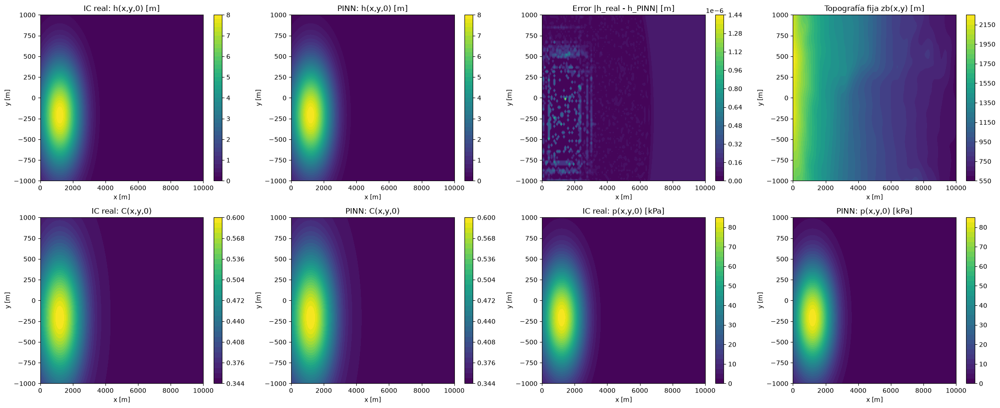

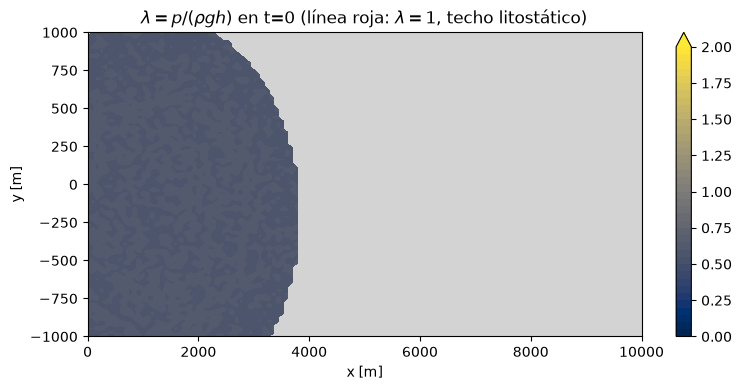

In [10]:
# ============================================================
# 11) VERIFICACIÓN DE CONDICIÓN INICIAL  (h, C y AHORA TAMBIÉN p)
# ============================================================
nx, ny = 120, 80
xg = np.linspace(x_min, x_max, nx).astype(np.float32)
yg = np.linspace(y_min, y_max, ny).astype(np.float32)
X, Y = np.meshgrid(xg, yg, indexing='xy')

Xf = X.reshape(-1, 1)
Yf = Y.reshape(-1, 1)
T0 = np.zeros_like(Xf, dtype=np.float32)

h_pred0, u_pred0, v_pred0, C_pred0, p_pred0 = predict_fields(
    tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf), tf.convert_to_tensor(T0))

h0_map_pred = h_pred0.numpy().reshape(ny, nx)
C0_map_pred = C_pred0.numpy().reshape(ny, nx)
p0_map_pred = p_pred0.numpy().reshape(ny, nx)
zb_map = zb0_physical(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf)).numpy().reshape(ny, nx)

h0_map_true = ic_h_physical(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf)).numpy().reshape(ny, nx)
C0_map_true = ic_C_physical(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf)).numpy().reshape(ny, nx)
p0_map_true = ic_p_physical(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf)).numpy().reshape(ny, nx)

lam0_map = p0_map_pred / np.maximum(rho_m * g * h0_map_pred, 1e-9)

# ------------------------------------------------------------
# CHEQUEO CUANTITATIVO. El ansatz hace EXACTAS las IC de h, u, v, C y p.
# p no tiene techo litostático: la fracción con lambda > 1 hay que vigilarla.
# ------------------------------------------------------------
err_h = np.abs(h0_map_true - h0_map_pred).max()
err_C = np.abs(C0_map_true - C0_map_pred).max()
err_p = np.abs(p0_map_true - p0_map_pred).max()
print("Error máximo de la condición inicial:")
print(f"  |h_real - h_PINN|_inf = {err_h:.3e} m      {'OK (ansatz duro)' if err_h < 1e-4 else '<-- REVISAR'}")
print(f"  |C_real - C_PINN|_inf = {err_C:.3e}        {'OK (ansatz duro)' if err_C < 1e-4 else '<-- REVISAR'}")
print(f"  |p_real - p_PINN|_inf = {err_p:.3e} Pa     "
      f"{'OK' if err_p < 1e3 else '<-- p NO TIENE ANSATZ DE IC: la condición inicial de presión de poros NO se está imponiendo'}")
print()
# lambda solo en la zona mojada: donde h ~ 1e-20 el cociente p/(rho g h) no tiene
# sentido físico (p queda en su piso numérico ~0.02 Pa y no afecta la fricción)
wet0 = h0_map_pred > 0.1
lam0_wet = lam0_map[wet0]
print(f"  lambda = p/(rho*g*h) en t=0 (zona mojada h>0.1 m):  min={lam0_wet.min():.3f}  "
      f"mediana={np.median(lam0_wet):.3f}  max={lam0_wet.max():.3f}")
print(f"  lambda deseado por ic_p_physical: {lambda_0:.3f} (uniforme)")
print(f"  fracción de la zona mojada con lambda > 1 (físicamente imposible): "
      f"{100.0*(lam0_wet > 1.0).mean():.1f}%")

# GATE DE MOVILIDAD: el lahar solo puede arrancar donde mu_eff < tan(theta)
zbx_g, zby_g = grad_zb_fixed(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf))
tan_map = np.sqrt(zbx_g.numpy()**2 + zby_g.numpy()**2).reshape(ny, nx)
mu0_map = mu_eff(C_pred0, p_pred0, h_pred0).numpy().reshape(ny, nx)
movil0 = 100.0 * (mu0_map[wet0] < tan_map[wet0]).mean()
print(f"\n  Zona mojada (h>0.1 m) con mu_eff < tan(theta) en t=0: {movil0:.1f}%   "
      f"(mu_eff mediano {np.median(mu0_map[wet0]):.3f} vs tan(theta) {np.median(tan_map[wet0]):.3f})")
if movil0 < 50.0:
    print("  *** Con estos parámetros la solución exacta es un lahar DETENIDO: subir lambda_0 ***")

fig, axes = plt.subplots(2, 4, figsize=(22, 9))
panels = [
    (h0_map_true, "IC real: h(x,y,0) [m]", None),
    (h0_map_pred, "PINN: h(x,y,0) [m]", None),
    (np.abs(h0_map_true - h0_map_pred), "Error |h_real - h_PINN| [m]", None),
    (zb_map, "Topografía fija zb(x,y) [m]", None),
    (C0_map_true, "IC real: C(x,y,0)", None),
    (C0_map_pred, "PINN: C(x,y,0)", None),
    (p0_map_true / 1e3, "IC real: p(x,y,0) [kPa]", None),
    (p0_map_pred / 1e3, "PINN: p(x,y,0) [kPa]", None),
]
for ax, (Z, title, _) in zip(axes.ravel(), panels):
    cs = ax.contourf(X, Y, Z, levels=40)
    ax.set_title(title); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
    plt.colorbar(cs, ax=ax)
plt.tight_layout(); plt.show()

# Mapa de lambda inicial: hace visible si p respeta el techo litostático
fig, ax = plt.subplots(figsize=(8, 4))
lam0_plot = np.ma.masked_where(~wet0, lam0_map)
ax.set_facecolor('lightgrey')
cs = ax.contourf(X, Y, np.clip(lam0_plot, 0, 2), levels=np.linspace(0, 2, 41),
                 cmap='cividis', extend='max')
ax.contour(X, Y, lam0_plot, levels=[1.0], colors='r', linewidths=2)
ax.set_title(r"$\lambda = p/(\rho g h)$ en t=0 (línea roja: $\lambda=1$, techo litostático)")
ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]")
plt.colorbar(cs, ax=ax); plt.tight_layout(); plt.show()


 t [s]   X_c [m]   dXc/dt     U_c  |u|cuerpo   frente  lambda  %lam>1  %movil    masa   m+sal
     0    1351.2   101.83    0.00       0.00     3025   0.600     0.0    98.5   1.000   1.000
    50    6442.8    52.96    0.92       1.77     8403   0.569     0.6    96.2   0.421   0.421
   100    6647.2     2.31    0.87       1.95     8487   0.564     0.2    97.5   0.656   0.656
   150    6674.1     0.45    0.88       1.99     8571   0.563     0.1    97.9   0.721   0.721
   200    6692.2     0.35    0.88       2.03     8571   0.564     0.2    97.9   0.768   0.768
   250    6708.7     0.32    0.88       2.05     8571   0.563     0.1    98.4   0.810   0.810
   300    6724.5     0.31    0.88       2.07     8571   0.563     0.2    98.4   0.847   0.847
   350    6739.9     0.30    0.89       2.08     8655   0.563     0.2    98.2   0.881   0.881
   400    6754.6     0.29    0.89       2.10     8655   0.563     0.2    98.5   0.912   0.912
   450    6769.4     0.29    0.89       2.11     8655   0.56

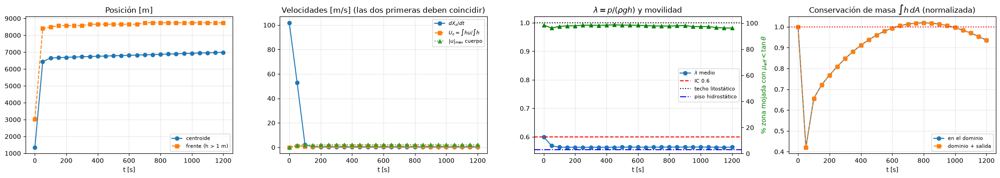

In [11]:
# ============================================================
# 12) DIAGNÓSTICO TEMPORAL: ¿se mueve el lahar y se conserva la masa?
# ============================================================
# Consistencia cinemática: si se conserva la masa y no hay flujo por las fronteras,
#   d/dt [ int x h dA ] = int h u dA   =>   dX_c/dt = U_c = (int h u dA)/(int h dA)
# Si dX_c/dt >> U_c, el centroide avanza porque la red CREA masa aguas abajo,
# no porque la transporte. Esa es la prueba de que el movimiento es físico.
t_check = np.linspace(0.0, Tmax, 25)
cell_area = (xg[1] - xg[0]) * (yg[1] - yg[0])
Xr = Xf.ravel()
zbx_g, zby_g = grad_zb_fixed(tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf))
tan_f = np.sqrt(zbx_g.numpy()**2 + zby_g.numpy()**2).ravel()

cent, Uc, ucore, front, lam_c, lam_gt1, movil, mass, qout = [], [], [], [], [], [], [], [], []
for tv in t_check:
    Tf = np.full_like(Xf, tv, dtype=np.float32)
    hp, up, vp, Cp, pp = predict_fields(
        tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf), tf.convert_to_tensor(Tf))
    mu_f = mu_eff(Cp, pp, hp).numpy().ravel()
    hh = hp.numpy().ravel(); uu = up.numpy().ravel()
    vv = vp.numpy().ravel(); pz = pp.numpy().ravel()
    w = np.maximum(hh, 0.0)
    cent.append(float((Xr * w).sum() / max(w.sum(), 1e-12)))
    Uc.append(float((w * uu).sum() / max(w.sum(), 1e-12)))          # velocidad media ponderada por h
    core = hh > 1.0                                                  # cuerpo del lahar (no la película delgada)
    ucore.append(float(np.sqrt(uu[core]**2 + vv[core]**2).max()) if core.any() else 0.0)
    front.append(float(Xr[core].max()) if core.any() else np.nan)    # frente del cuerpo (h > 1 m)
    wet = hh > 0.1
    lam = pz[wet] / (rho_m * g * hh[wet])
    lam_c.append(float(lam.mean()) if wet.any() else np.nan)
    lam_gt1.append(100.0 * float((lam > 1.0).mean()) if wet.any() else np.nan)
    movil.append(100.0 * float((mu_f[wet] < tan_f[wet]).mean()) if wet.any() else np.nan)
    mass.append(float(w.sum() * cell_area))
    # caudal que sale por x = Lx (se integra en el tiempo más abajo)
    hq, uq, _, _, _ = predict_fields(tf.constant(np.full((ny, 1), x_max, np.float32)),
                                     tf.constant(yg.reshape(-1, 1)), tf.constant(np.full((ny, 1), tv, np.float32)))
    qout.append(float((hq.numpy() * uq.numpy()).sum() * (yg[1] - yg[0])))

dXc = np.gradient(np.array(cent), t_check)                           # velocidad del centroide
# volumen acumulado que salió por x = Lx: masa + salida debe ser constante
vout = np.concatenate([[0.0], np.cumsum(0.5 * (np.array(qout[1:]) + np.array(qout[:-1])) * np.diff(t_check))])
bal = (np.array(mass) + vout) / mass[0]
print(f"{'t [s]':>6} {'X_c [m]':>9} {'dXc/dt':>8} {'U_c':>7} {'|u|cuerpo':>10} {'frente':>8} "
      f"{'lambda':>7} {'%lam>1':>7} {'%movil':>7} {'masa':>7} {'m+sal':>7}")
for k, tv in enumerate(t_check):
    print(f"{tv:6.0f} {cent[k]:9.1f} {dXc[k]:8.2f} {Uc[k]:7.2f} {ucore[k]:10.2f} {front[k]:8.0f} "
          f"{lam_c[k]:7.3f} {lam_gt1[k]:7.1f} {movil[k]:7.1f} {mass[k]/mass[0]:7.3f} {bal[k]:7.3f}")
print("  dXc/dt, U_c, |u|cuerpo en m/s | frente = x máx. con h > 1 m | %movil = zona mojada con mu_eff < tan(theta)")
print("  m+sal = (volumen en el dominio + volumen que salió por x = Lx)/V0: debe ser 1")
print("  Nota: cuando el lahar sale por x = Lx, X_c y U_c dejan de ser comparables (la masa se va del dominio).")

desp = cent[-1] - cent[0]
incons = np.abs(dXc - np.array(Uc)).mean()
print(f"\n>>> Desplazamiento del centroide en {Tmax:.0f} s: {desp:+.1f} m (velocidad media {desp/Tmax:+.2f} m/s)")
print(f">>> Frente del cuerpo: {front[0]:.0f} m -> {front[-1]:.0f} m")
print(f">>> Masa en el dominio: {mass[-1]/mass[0]:.4f} | salió por x=Lx: {vout[-1]/mass[0]:.4f} | balance: {bal[-1]:.4f} (debe ser 1)")
print(f">>> lambda: {lam_c[0]:.3f} (t=0) -> {lam_c[-1]:.3f} (t={Tmax:.0f});  máx. % con lambda>1: {np.nanmax(lam_gt1):.1f}%")
print(f">>> |dXc/dt - U_c| medio = {incons:.2f} m/s  (debe ser ~0 si el transporte es físico)")
if desp < 50.0:
    print("\n*** EL FLUJO SIGUE BLOQUEADO por fricción. ***")
if np.abs(bal - 1.0).max() > 0.05:
    print("*** LA MASA NO SE CONSERVA (balance con la salida por x = Lx fuera de ±5%). ***")
if incons > 0.5:
    print("*** El centroide NO se mueve con la velocidad del flujo: masa creada/destruida, no transportada. ***")
if np.nanmax(lam_gt1) > 1.0:
    print("*** Hay zona mojada con lambda > 1: la red está apagando la fricción con presión imposible. ***")

fig, axes = plt.subplots(1, 4, figsize=(22, 4))
axes[0].plot(t_check, cent, 'o-', label='centroide')
axes[0].plot(t_check, front, 's--', label='frente (h > 1 m)')
axes[0].set_title("Posición [m]"); axes[0].legend(fontsize=8)
axes[1].plot(t_check, dXc, 'o-', label=r'$dX_c/dt$')
axes[1].plot(t_check, Uc, 's--', label=r'$U_c=\int hu/\int h$')
axes[1].plot(t_check, ucore, '^:', label=r'$|u|_{max}$ cuerpo')
axes[1].set_title("Velocidades [m/s] (las dos primeras deben coincidir)"); axes[1].legend(fontsize=8)
axes[2].plot(t_check, lam_c, 'o-', label=r'$\lambda$ medio')
axes[2].axhline(lambda_0, ls='--', c='r', label=f'IC {lambda_0}')
axes[2].axhline(1.0, ls=':', c='k', label='techo litostático')
axes[2].axhline(lambda_hydro, ls='-.', c='b', label='piso hidrostático')
ax2b = axes[2].twinx(); ax2b.plot(t_check, movil, 'g^-', label='% móvil'); ax2b.set_ylim(0, 105)
ax2b.set_ylabel(r'% zona mojada con $\mu_{eff}<\tan\theta$', color='g')
axes[2].set_title(r"$\lambda = p/(\rho g h)$ y movilidad"); axes[2].legend(fontsize=8, loc='center right')
axes[3].plot(t_check, np.array(mass)/mass[0], 'o-', label='en el dominio')
axes[3].plot(t_check, bal, 's--', label='dominio + salida')
axes[3].axhline(1.0, ls=':', c='r'); axes[3].legend(fontsize=8)
axes[3].set_title(r"Conservación de masa $\int h\,dA$ (normalizada)")
for a in axes: a.set_xlabel("t [s]"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()


In [12]:
# ============================================================
# 13) ANIMACIÓN: h, |u|, C, lambda
# ============================================================
import matplotlib.animation as animation
from IPython.display import HTML

# OJO: ya no hay condición de Neumann sobre C (loss_C_flux fue eliminado y
# kappa_C = 0). La única BC activa es h = 0 tipo Dirichlet en y = +-Ly/2.
etiqueta = f"5PDE_chi{chi_p:.2f}_kC{kappa_C:.1f}_T{Tmax:.0f}"
if TOPO_SCENARIO == 4:
    etiqueta = f"5PDE_DEM_az{flow_az:.0f}_chi{chi_p:.2f}_T{Tmax:.0f}"
num_frames = 60
t_values = np.linspace(0.0, Tmax, num_frames)

# Niveles FIJOS. contourf con levels=<int> recalcula los niveles frame a frame
# a partir del rango de los datos e IGNORA vmin/vmax para elegirlos, así que
# la escala de color cambiaba en cada cuadro y la animación era engañosa.
lv_h   = np.linspace(0.0, 8.0, 41)
lv_u   = np.linspace(0.0, 20.0, 41)
lv_C   = np.linspace(0.2, Cmax, 41)
lv_lam = np.linspace(0.0, 1.5, 41)

fig, axes = plt.subplots(2, 2, figsize=(16, 9))
fig.suptitle(f"Lahar 5-EDP — {Tmax:.0f} s — "
             rf"$\chi_p$={chi_p}, $\kappa_C$={kappa_C}, $\tau_p$={tau_p:.0f} s")

def update(frame):
    for a in axes.ravel(): a.clear()
    tv = t_values[frame]
    Tf = np.full_like(Xf, tv, dtype=np.float32)
    hp, up, vp, Cp, pp = predict_fields(
        tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf), tf.convert_to_tensor(Tf))

    h_map = hp.numpy().reshape(ny, nx)
    U_map = np.sqrt(up.numpy()**2 + vp.numpy()**2).reshape(ny, nx)
    C_map = Cp.numpy().reshape(ny, nx)
    lam_map = (pp.numpy() / np.maximum(rho_m * g * hp.numpy(), 1e-9)).reshape(ny, nx)

    # Máscara por ESPESOR, no por concentración: C vale ~0.35 de fondo en todo
    # el dominio, así que la máscara antigua (C < 0.01) no se activaba nunca.
    dry = h_map < 0.05
    U_m, C_m, lam_m = (np.ma.masked_where(dry, Z) for Z in (U_map, C_map, lam_map))

    for a in axes.ravel(): a.set_facecolor('lightgrey')
    axes[0, 0].contourf(X, Y, h_map, levels=lv_h, cmap='viridis', extend='max')
    axes[0, 0].set_title(f"Espesor h   t={tv:.0f} s   [m]")
    axes[0, 1].contourf(X, Y, U_m, levels=lv_u, cmap='magma', extend='max')
    axes[0, 1].set_title(f"Velocidad |u|   t={tv:.0f} s   [m/s]")
    axes[1, 0].contourf(X, Y, C_m, levels=lv_C, cmap='plasma', extend='both')
    axes[1, 0].set_title(f"Concentración C   t={tv:.0f} s")
    axes[1, 1].contourf(X, Y, lam_m, levels=lv_lam, cmap='cividis', extend='max')
    axes[1, 1].contour(X, Y, np.ma.masked_where(dry, lam_map), levels=[1.0],
                       colors='r', linewidths=1.5)
    axes[1, 1].set_title(rf"$\lambda = p/(\rho g h)$   t={tv:.0f} s   (rojo: $\lambda=1$)")
    for a in axes.ravel():
        a.contour(X, Y, zb_map, levels=15, colors='k', linewidths=0.4, alpha=0.5)  # curvas de nivel de z_b
        a.set_xlabel("x [m]"); a.set_ylabel("y [m]")

print("Generando animación, por favor espera...")
ani = animation.FuncAnimation(fig, update, frames=num_frames, interval=100)
aniname = f"Prediccion {etiqueta}.gif"
ani.save(aniname, writer='pillow', fps=10)
print(f"GIF guardado como '{aniname}'")
plt.close()
display(HTML(ani.to_jshtml()))


Generando animación, por favor espera...
GIF guardado como 'Prediccion 5PDE_DEM_az335_chi0.80_T1200.gif'


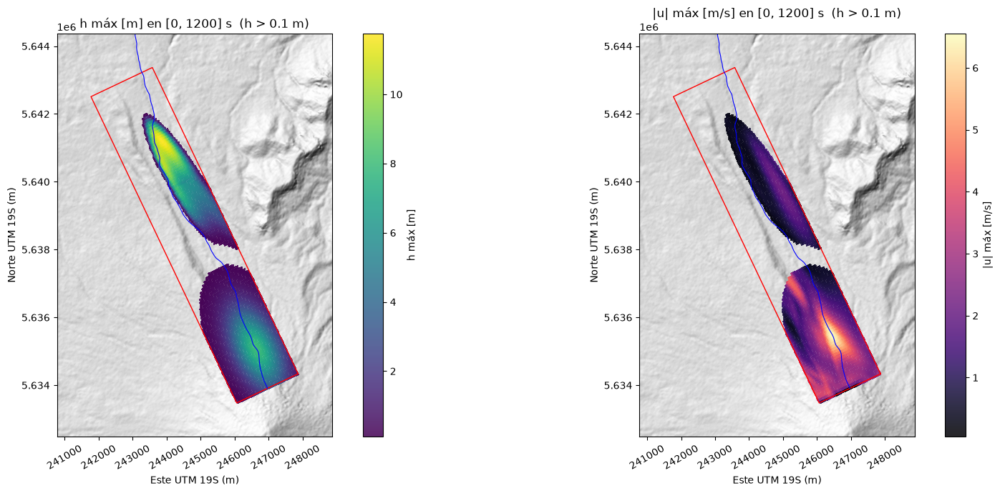

In [13]:
# ============================================================
# 14) MAPA DE INUNDACIÓN SOBRE EL DEM (solo TOPO_SCENARIO = 4)
# ============================================================
# h y |u| máximos en todo [0, Tmax], llevados de vuelta a UTM 19S sobre el relieve.
if TOPO_SCENARIO == 4:
    h_max = np.zeros((ny, nx)); u_max = np.zeros((ny, nx))
    for tv in np.linspace(0.0, Tmax, 41):
        Tf = np.full_like(Xf, tv, dtype=np.float32)
        hp, up, vp, _, _ = predict_fields(
            tf.convert_to_tensor(Xf), tf.convert_to_tensor(Yf), tf.convert_to_tensor(Tf))
        h_max = np.maximum(h_max, hp.numpy().reshape(ny, nx))
        u_max = np.maximum(u_max, np.sqrt(up.numpy()**2 + vp.numpy()**2).reshape(ny, nx))
    EG, NG = local_to_utm(X, Y)                     # grilla de evaluación en UTM

    fig, axes = plt.subplots(1, 2, figsize=(17, 7))
    for a, Zm, lab, cmap in [(axes[0], h_max, "h máx [m]", "viridis"),
                             (axes[1], u_max, "|u| máx [m/s]", "magma")]:
        a.imshow(hill_dem, cmap="gray", extent=ext_dem)
        pc = a.pcolormesh(EG, NG, np.ma.masked_where(h_max < 0.1, Zm), cmap=cmap,
                          shading="auto", alpha=0.85)
        a.plot(cE, cN, "r-", lw=1)
        a.plot(path_EN[:, 0], path_EN[:, 1], "b-", lw=0.8)
        a.set_xlim(cE.min() - 1000, cE.max() + 1000); a.set_ylim(cN.min() - 1000, cN.max() + 1000)
        a.set_xlabel("Este UTM 19S (m)"); a.set_ylabel("Norte UTM 19S (m)")
        a.tick_params(axis="x", labelrotation=30)
        a.set_title(f"{lab} en [0, {Tmax:.0f}] s  (h > 0.1 m)")
        plt.colorbar(pc, ax=a, label=lab)
    plt.tight_layout(); plt.show()


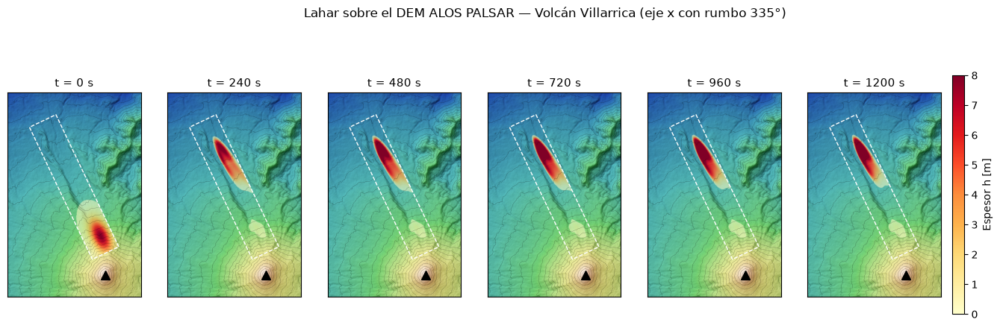

Generando animación sobre el DEM, por favor espera...
GIF guardado como 'Lahar DEM 3D 5PDE_DEM_az335_chi0.80_T1200.gif'


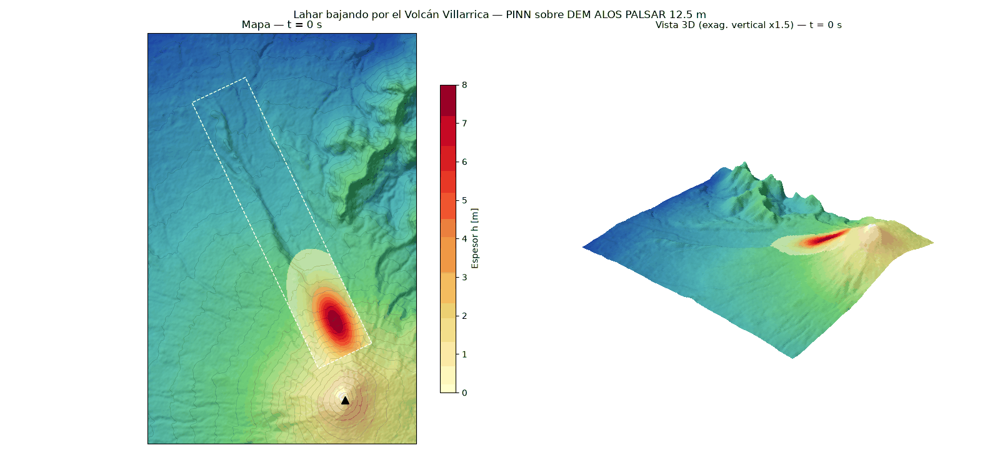

In [14]:
# ============================================================
# 15) LAHAR BAJANDO POR EL VOLCÁN: mapa + vista 3D sobre el DEM (solo TOPO_SCENARIO = 4)
# ============================================================
# La PINN se evalúa directamente en una grilla UTM alineada con el DEM (los puntos que caen
# dentro del dominio rotado); fuera del dominio el terreno queda seco.
# Salidas: figura con instantáneas (mapa) y GIF con mapa + vista 3D.
if TOPO_SCENARIO == 4:
    import matplotlib.animation as animation
    from matplotlib.colors import LightSource, Normalize
    from IPython.display import Image, display

    VIS_RES = 25.0        # resolución del mapa [m]
    VIS_RES_3D = 60.0     # resolución de la vista 3D [m] (más fino = más lento)
    VIS_MARGIN = 1500.0   # margen alrededor del dominio y la cumbre [m]
    H_MIN = 0.1           # h mínimo para pintar el lahar [m]
    H_COLOR_MAX = 8.0     # tope de la escala de color de h [m]
    VERT_EXAG = 1.5       # exageración vertical de la vista 3D
    VIEW_ELEV = 35.0      # elevación de la cámara 3D [°]
    VIEW_FROM = (flow_az - 110.0) % 360.0   # rumbo desde donde mira la cámara (lado izquierdo del flujo)
    N_FRAMES_VIS = 40
    N_SNAPS = 6
    cmap_h = plt.cm.YlOrRd
    norm_h = Normalize(0.0, H_COLOR_MAX)

    # --- Ventana UTM: dominio + cumbre + margen, dentro del DEM ---
    E_lo = max(min(cE.min(), E_top) - VIS_MARGIN, ext_dem[0])
    E_hi = min(max(cE.max(), E_top) + VIS_MARGIN, ext_dem[1])
    N_lo = max(min(cN.min(), N_top) - VIS_MARGIN, ext_dem[2])
    N_hi = min(max(cN.max(), N_top) + VIS_MARGIN, ext_dem[3])

    def vis_grid(res):
        """Grilla UTM (filas de norte a sur), cota del DEM y coordenadas locales de cada punto."""
        Ev = np.arange(E_lo + res / 2, E_hi, res)
        Nv = np.arange(N_hi - res / 2, N_lo, -res)
        EE, NN = np.meshgrid(Ev, Nv)
        zz = dem_sample(dem, EE, NN)
        xl, yl = utm_to_local(EE, NN)
        inside = (xl >= x_min) & (xl <= x_max) & (yl >= y_min) & (yl <= y_max)
        return EE, NN, zz, xl.astype(np.float32), yl.astype(np.float32), inside

    _CHUNK = 32768   # tamaño fijo de lote: evita re-trazar predict_fields en cada llamada
    def h_on_grid(xl, yl, inside, tv):
        """h de la PINN en los puntos 'inside' de la grilla, en el instante tv; 0 fuera."""
        xs, ys = xl[inside], yl[inside]
        out = np.empty(xs.size, np.float32)
        for i in range(0, xs.size, _CHUNK):
            n = min(_CHUNK, xs.size - i)
            xb = np.zeros((_CHUNK, 1), np.float32); yb = np.zeros((_CHUNK, 1), np.float32)
            xb[:n, 0], yb[:n, 0] = xs[i:i + n], ys[i:i + n]
            hb, _, _, _, _ = predict_fields(tf.constant(xb), tf.constant(yb),
                                            tf.constant(np.full((_CHUNK, 1), tv, np.float32)))
            out[i:i + n] = hb.numpy()[:n, 0]
        h = np.zeros(xl.shape, np.float32)
        h[inside] = out
        return h

    ls = LightSource(azdeg=315, altdeg=45)
    def base_rgb(zz, res):
        """Relieve sombreado con tinte hipsométrico suave (RGBA)."""
        rgb = ls.shade(zz, cmap=plt.cm.gist_earth, blend_mode="soft", vert_exag=2,
                       dx=res, dy=res, vmin=zz.min() - 300, vmax=zz.max() + 300)
        return rgb

    def blend_lahar(rgb, h):
        """Pinta el lahar (h > H_MIN) sobre el relieve; opacidad crece con h."""
        out = rgb.copy()
        wet = h > H_MIN
        a = np.clip(0.55 + 0.45 * h / H_COLOR_MAX, 0.0, 1.0)[..., None]
        out[wet] = (1 - a[wet]) * rgb[wet] + a[wet] * cmap_h(norm_h(h[wet]))
        return out

    EE, NN, zz, xl, yl, inside = vis_grid(VIS_RES)
    EE3, NN3, zz3, xl3, yl3, inside3 = vis_grid(VIS_RES_3D)
    rgb_map, rgb_3d = base_rgb(zz, VIS_RES), base_rgb(zz3, VIS_RES_3D)
    ext_vis = (EE[0, 0] - VIS_RES / 2, EE[0, -1] + VIS_RES / 2, NN[-1, 0] - VIS_RES / 2, NN[0, 0] + VIS_RES / 2)
    lev_z = np.arange(0, 3000, 100)

    def draw_map(ax, h, tv):
        ax.imshow(blend_lahar(rgb_map, h), extent=ext_vis, interpolation="bilinear")
        ax.contour(EE, NN, zz, levels=lev_z, colors="k", linewidths=0.25, alpha=0.4)
        ax.plot(cE, cN, "w--", lw=1)
        ax.plot(E_top, N_top, "k^", ms=8)
        ax.set_xlim(ext_vis[:2]); ax.set_ylim(ext_vis[2:])
        ax.set_title(f"t = {tv:.0f} s", fontsize=11)
        ax.set_xticks([]); ax.set_yticks([])

    # --- (a) Instantáneas en mapa ---
    t_snaps = np.linspace(0.0, Tmax, N_SNAPS)
    fig, axes = plt.subplots(1, N_SNAPS, figsize=(3.2 * N_SNAPS, 5.2))
    for a, tv in zip(axes, t_snaps):
        draw_map(a, h_on_grid(xl, yl, inside, tv), tv)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm_h, cmap=cmap_h), ax=axes, shrink=0.8,
                 label="Espesor h [m]", pad=0.01)
    fig.suptitle(f"Lahar sobre el DEM ALOS PALSAR — Volcán Villarrica (eje x con rumbo {flow_az:.0f}°)")
    plt.show()

    # --- (b) Animación: mapa + vista 3D ---
    fig = plt.figure(figsize=(16, 7.5))
    ax_m = fig.add_subplot(1, 2, 1)
    ax_3 = fig.add_subplot(1, 2, 2, projection="3d")
    fig.colorbar(plt.cm.ScalarMappable(norm=norm_h, cmap=cmap_h), ax=ax_m, shrink=0.75, label="Espesor h [m]")

    surf = ax_3.plot_surface(EE3, NN3, zz3 * VERT_EXAG, facecolors=rgb_3d, rstride=1, cstride=1,
                             linewidth=0, antialiased=False, shade=False)
    ax_3.view_init(elev=VIEW_ELEV, azim=90.0 - VIEW_FROM)
    ax_3.set_box_aspect((np.ptp(EE3), np.ptp(NN3), VERT_EXAG * np.ptp(zz3)))
    ax_3.set_axis_off()
    title_3d = ax_3.set_title("", fontsize=11)

    def update_vis(frame):
        tv = t_vis[frame]
        ax_m.clear()
        draw_map(ax_m, h_on_grid(xl, yl, inside, tv), tv)
        ax_m.set_title(f"Mapa — t = {tv:.0f} s")
        h3 = h_on_grid(xl3, yl3, inside3, tv)
        # plot_surface usa el color de la esquina superior izquierda de cada celda, fila por fila
        surf.set_facecolor(blend_lahar(rgb_3d, h3)[:-1, :-1].reshape(-1, 4))
        title_3d.set_text(f"Vista 3D (exag. vertical x{VERT_EXAG:g}) — t = {tv:.0f} s")
        return []

    t_vis = np.linspace(0.0, Tmax, N_FRAMES_VIS)
    fig.suptitle("Lahar bajando por el Volcán Villarrica — PINN sobre DEM ALOS PALSAR 12.5 m")
    plt.tight_layout()
    print("Generando animación sobre el DEM, por favor espera...")
    ani_vis = animation.FuncAnimation(fig, update_vis, frames=N_FRAMES_VIS, interval=150)
    gif_vis = f"Lahar DEM 3D {etiqueta}.gif"
    ani_vis.save(gif_vis, writer="pillow", fps=8)
    plt.close(fig)
    print(f"GIF guardado como '{gif_vis}'")
    display(Image(filename=gif_vis))
else:
    print("TOPO_SCENARIO analítico: esta figura necesita el DEM (TOPO_SCENARIO = 4).")
